# MarketMind — Real NIFTY 50 Regime Model Training & Comparison

This notebook uses the **bundled historical NIFTY 50 1-minute OHLC CSVs** under `data/raw/nifty50/1min/`. It builds 15-minute bars, engineers OHLC-only features, compares four unsupervised clustering algorithms, and saves reproducible metrics.

> **Scope and honesty:** The historical data has no independently supplied market-regime labels. Therefore this notebook does not report classification accuracy, ARI, or NMI. It reports internal clustering metrics, noise share, temporal persistence, and runtime. These measure different properties and do not establish trading profitability. The research feature set excludes volume because volume is absent from most historical years. This experiment does not silently replace the application's seven-feature production model or generate a production-compatible artifact.

Run from the `MarketMind` project root after installing `requirements.txt`.


In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Find the MarketMind project root regardless of whether Jupyter starts in
# the project folder, its research folder, or a parent folder.
_current = Path.cwd().resolve()
_candidates = [_current, *_current.parents]
ROOT = next(
    (p for p in _candidates
     if (p / "data" / "raw" / "nifty50" / "1min").is_dir()),
    None
)

# Also support launching Jupyter from a folder above MarketMind.
if ROOT is None:
    matches = list(_current.glob("MarketMind/data/raw/nifty50/1min"))
    if matches:
        ROOT = matches[0].parents[3]

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the MarketMind project data folder. Expected "
        "MarketMind/data/raw/nifty50/1min. Start Jupyter from the MarketMind "
        "folder or its research folder, and confirm the CSV files are extracted."
    )

DATA_DIR = ROOT / "data" / "raw" / "nifty50" / "1min"
OUT_DIR = ROOT / "research" / "real_data_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
MAX_TRAIN_ROWS = 10000       # common fit cap keeps DBSCAN/Agglomerative practical
MAX_TEST_ROWS = 10000        # common held-out evaluation cap

print("Notebook started from:", _current)
print("Detected project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())
print("Results will be saved to:", OUT_DIR)


Notebook started from: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\research
Detected project root: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind
Data directory: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min
Data directory exists: True
Results will be saved to: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\real_data_results


## 1. Load and audit the bundled 1-minute data

Only the 1-minute CSVs are used here. The separate 15-second files are retained in the project but excluded so that the comparison has one consistent input timeframe. Timestamps in these files are local IST wall-clock times.

In [2]:
files = sorted(DATA_DIR.rglob("*.csv"))
print(f"Searching: {DATA_DIR.resolve()}")
print(f"CSV files found: {len(files)}")
if not files:
    raise FileNotFoundError(
        f"No 1-minute CSV files found under {DATA_DIR.resolve()}. "
        "Check that the extracted files are in MarketMind/data/raw/nifty50/1min."
    )

frames = []
file_audit = []
for path in files:
    df = pd.read_csv(path)
    required = ["Timestamp", "Open", "High", "Low", "Close"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"{path.name} is missing columns: {missing}")
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    for c in ["Open", "High", "Low", "Close"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    if "Volume" in df.columns:
        df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")
    frames.append(df)
    file_audit.append({"file": str(path.relative_to(ROOT)), "rows": len(df),
                       "start": str(df["Timestamp"].min()), "end": str(df["Timestamp"].max()),
                       "has_volume": "Volume" in df.columns})

raw = pd.concat(frames, ignore_index=True)
raw = raw.sort_values("Timestamp").reset_index(drop=True)
audit = {
    "files_loaded": len(files),
    "rows_loaded": int(len(raw)),
    "invalid_timestamps": int(raw["Timestamp"].isna().sum()),
    "duplicate_timestamps": int(raw["Timestamp"].duplicated().sum()),
    "missing_ohlc_cells": int(raw[["Open","High","Low","Close"]].isna().sum().sum()),
    "non_positive_ohlc_cells": int((raw[["Open","High","Low","Close"]] <= 0).sum().sum()),
    "ohlc_inconsistency_rows": int(((raw["High"] < raw[["Open","Close","Low"]].max(axis=1)) |
                                   (raw["Low"] > raw[["Open","Close","High"]].min(axis=1))).sum())
}
display(pd.DataFrame(file_audit))
display(pd.Series(audit, name="value").to_frame())


Searching: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min
CSV files found: 20


,file,rows,start,end,has_volume
0,data\raw\nifty50\1min\2017\NIFTY50_1min_2017.csv,69375,2017-04-03 09:15:00,2017-12-29 15:29:00,False
1,data\raw\nifty50\1min\2018\NIFTY50_1min_2018.csv,91874,2018-01-01 09:15:00,2018-12-31 15:29:00,False
2,data\raw\nifty50\1min\2019\NIFTY50_1min_2019.csv,91500,2019-01-01 09:15:00,2019-12-31 15:29:00,False
3,data\raw\nifty50\1min\2020\NIFTY50_1min_2020.csv,94125,2020-01-01 09:15:00,2020-12-31 15:29:00,False
4,data\raw\nifty50\1min\2021\NIFTY50_1min_2021.csv,92668,2021-01-01 09:15:00,2021-12-31 15:29:00,False
5,data\raw\nifty50\1min\2022\NIFTY50_1min_2022.csv,92617,2022-01-03 09:15:00,2022-12-30 15:29:00,False
6,data\raw\nifty50\1min\2023\NIFTY50_1min_2023.csv,91931,2023-01-02 09:15:00,2023-12-29 15:29:00,False
7,data\raw\nifty50\1min\2024\NIFTY50_1min_2024.csv,92523,2024-01-01 09:15:00,2024-12-31 15:29:00,False
8,data\raw\nifty50\1min\2025\NIFTY50_1min_2025.csv,93060,2025-01-01 09:15:00,2025-12-31 15:29:00,False
9,data\raw\nifty50\1min\2026\NIFTY50_1min_2026-0...,7500,2026-01-01 09:15:00,2026-01-30 15:29:00,True


,value
files_loaded,20
rows_loaded,890728
invalid_timestamps,0
duplicate_timestamps,0
missing_ohlc_cells,0
non_positive_ohlc_cells,0
ohlc_inconsistency_rows,0


In [3]:
# Remove invalid rows and duplicate timestamps; retain the first chronological observation.
raw = raw.dropna(subset=["Timestamp","Open","High","Low","Close"])
raw = raw.drop_duplicates(subset=["Timestamp"], keep="first")
raw = raw[(raw[["Open","High","Low","Close"]] > 0).all(axis=1)]
raw = raw[raw["High"] >= raw[["Open","Close","Low"]].max(axis=1)]
raw = raw[raw["Low"] <= raw[["Open","Close","High"]].min(axis=1)]
raw = raw.sort_values("Timestamp").set_index("Timestamp")

# Restrict to the regular NSE cash-market session.
raw = raw.between_time("09:15", "15:29")
raw["session_date"] = raw.index.date

# Aggregate each session independently; 15-minute buckets align to 09:15 IST.
def resample_session(day):
    day = day.drop(columns=["session_date"])
    agg = {"Open":"first", "High":"max", "Low":"min", "Close":"last"}
    if "Volume" in day.columns:
        agg["Volume"] = "sum"
    out = day.resample("15min", origin="start_day", offset="9h15min",
                       label="left", closed="left").agg(agg)
    return out.dropna(subset=["Open","High","Low","Close"])

bars = pd.concat([resample_session(g) for _, g in raw.groupby("session_date")])
bars = bars.sort_index()
bars = bars[(bars.index.time >= pd.Timestamp("09:15").time()) &
            (bars.index.time <= pd.Timestamp("15:15").time())]
print(f"Clean 1-minute rows: {len(raw):,}")
print(f"15-minute bars: {len(bars):,}")
print("Coverage:", bars.index.min(), "to", bars.index.max())
display(bars.head())


Clean 1-minute rows: 890,607
15-minute bars: 59,378
Coverage: 2017-04-03 09:15:00 to 2026-11-17 15:15:00


,Open,High,Low,Close,Volume
Timestamp,,,,,
2017-04-03 09:15:00,9219.63,9221.75,9193.50,9200.35,0.0
2017-04-03 09:30:00,9200.65,9208.80,9195.35,9197.50,0.0
2017-04-03 09:45:00,9197.80,9205.60,9192.40,9202.35,0.0
2017-04-03 10:00:00,9202.05,9209.35,9201.90,9205.90,0.0
2017-04-03 10:15:00,9205.90,9207.20,9198.85,9201.30,0.0


## 2. Explore price coverage and engineer features

The features are computed only from current and past bars. We use six OHLC-derived features so the same feature set is available across the full historical period; the dataset README notes that volume is only present in 2026 one-minute files.

,count,first,last,year_return_pct
Timestamp,,,,
2017-12-31,4625,9200.35,10527.90,14.429342
2018-12-31,6125,10522.80,10861.60,3.219675
2019-12-31,6100,10850.60,12177.10,12.225130
2020-12-31,6275,12221.90,13967.10,14.279286
2021-12-31,6178,14018.50,17364.25,23.866676
2022-12-31,6175,17462.35,18117.05,3.749209
2023-12-31,6125,18101.85,21728.30,20.033588
2024-12-31,6167,21700.80,23668.80,9.068790
2025-12-31,6204,23640.85,26141.85,10.579146


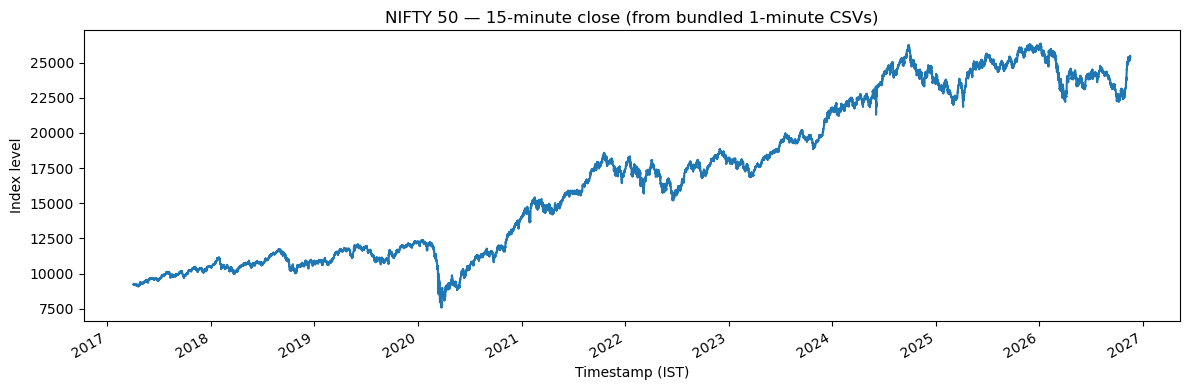

Feature rows: 59313 | features: ['ret_5', 'roll_vol', 'rsi', 'ma_diff', 'momentum', 'atr_pct']


,count,mean,std,min,25%,50%,75%,max
ret_5,59313.0,0.008375,0.450660,-11.497840,-0.152845,0.013180,0.174330,11.262615
roll_vol,59313.0,0.154018,0.127837,0.023405,0.091404,0.125586,0.178297,3.130192
rsi,59313.0,51.790650,19.132641,0.000000,37.471474,51.765376,66.362091,99.928622
ma_diff,59313.0,0.025616,0.501057,-5.031037,-0.219457,0.044475,0.289268,4.442814
momentum,59313.0,0.018783,0.637106,-12.380133,-0.240887,0.027888,0.288670,14.272556
atr_pct,59313.0,0.202110,0.127923,0.053371,0.133113,0.174461,0.233717,2.724547


In [4]:
daily = bars["Close"].resample("YE").agg(["count","first","last"])
daily["year_return_pct"] = (daily["last"] / daily["first"] - 1) * 100
display(daily)

plt.figure(figsize=(12,4))
bars["Close"].plot()
plt.title("NIFTY 50 — 15-minute close (from bundled 1-minute CSVs)")
plt.xlabel("Timestamp (IST)")
plt.ylabel("Index level")
plt.tight_layout()
plt.show()

close = bars["Close"]
prev_close = close.shift(1)
log_ret = np.log(close).diff()
delta = close.diff()
gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
loss = (-delta.clip(upper=0)).rolling(14, min_periods=14).mean()
rs = gain / loss.replace(0, np.nan)
rsi = 100 - (100 / (1 + rs))
tr = pd.concat([(bars["High"]-bars["Low"]),
                (bars["High"]-prev_close).abs(),
                (bars["Low"]-prev_close).abs()], axis=1).max(axis=1)
atr = tr.rolling(14, min_periods=14).mean()

features = pd.DataFrame(index=bars.index)
features["ret_5"] = np.log(close).diff(5) * 100
features["roll_vol"] = log_ret.rolling(20, min_periods=20).std() * 100
features["rsi"] = rsi
features["ma_diff"] = (close.rolling(20).mean() / close.rolling(50).mean() - 1) * 100
features["momentum"] = (close / close.shift(10) - 1) * 100
features["atr_pct"] = atr / close * 100
features = features.replace([np.inf,-np.inf], np.nan).dropna()
print("Feature rows:", len(features), "| features:", list(features.columns))
display(features.describe().T)


## 3. Chronological train/test split and preprocessing

The first 70% of observations are training data and the final 30% are held out. The scaler is fitted on training data only. Volatility and ATR are log-transformed before scaling, matching the transformation style used by the production GMM detector.

In [5]:
split_at = int(len(features) * TRAIN_FRACTION)
X_train_raw = features.iloc[:split_at].copy()
X_test_raw = features.iloc[split_at:].copy()

log_cols = ["roll_vol", "atr_pct"]
def transform_features(frame):
    out = frame.copy()
    for col in log_cols:
        out[col] = np.log(out[col].clip(lower=1e-9))
    return out

X_train_t = transform_features(X_train_raw)
X_test_t = transform_features(X_test_raw)

scaler = StandardScaler()
Z_train_all = scaler.fit_transform(X_train_t)
Z_test_all = scaler.transform(X_test_t)

rng = np.random.default_rng(RANDOM_STATE)
train_n = min(MAX_TRAIN_ROWS, len(Z_train_all))
test_n = min(MAX_TEST_ROWS, len(Z_test_all))
train_idx = np.sort(rng.choice(len(Z_train_all), size=train_n, replace=False))
test_idx = np.sort(rng.choice(len(Z_test_all), size=test_n, replace=False))
Z_train = Z_train_all[train_idx]
Z_test = Z_test_all[test_idx]
test_timestamps = X_test_raw.index[test_idx]
print("Chronological split:", len(X_train_raw), "train /", len(X_test_raw), "test")
print("Fit sample:", len(Z_train), "| held-out evaluation sample:", len(Z_test))


Chronological split: 41519 train / 17794 test
Fit sample: 10000 | held-out evaluation sample: 10000


## 4. Compare clustering algorithms

All four algorithms are fitted on the same deterministic sample from the training period and evaluated on the same held-out sample. K-Means and GMM have native prediction. Agglomerative clustering uses a nearest-training-centroid proxy. DBSCAN assigns a test point to its nearest training core point only when it is within `eps`; otherwise it is marked as noise (`-1`). These two proxy methods are approximations, not native out-of-sample prediction.

In [6]:
models = {
    "KMeans": KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE),
    "GMM": GaussianMixture(n_components=4, covariance_type="full", n_init=3,
                           random_state=RANDOM_STATE, reg_covar=1e-5),
    "Agglomerative": AgglomerativeClustering(n_clusters=4, linkage="ward"),
    "DBSCAN": DBSCAN(eps=0.8, min_samples=20)
}

def safe_internal_metrics(Z, labels):
    labels = np.asarray(labels)
    non_noise = labels != -1
    unique = np.unique(labels[non_noise])
    if non_noise.sum() < 3 or len(unique) < 2 or len(unique) >= non_noise.sum():
        return np.nan, np.nan, np.nan
    z = Z[non_noise]
    lab = labels[non_noise]
    return (silhouette_score(z, lab),
            davies_bouldin_score(z, lab),
            calinski_harabasz_score(z, lab))

results = []
predictions = {}
for name, model in models.items():
    start = time.perf_counter()
    if name == "KMeans" or name == "GMM":
        model.fit(Z_train)
        fit_seconds = time.perf_counter() - start
        pred_start = time.perf_counter()
        labels = model.predict(Z_test)
        predict_seconds = time.perf_counter() - pred_start
        train_labels = model.predict(Z_train)
    elif name == "Agglomerative":
        train_labels = model.fit_predict(Z_train)
        fit_seconds = time.perf_counter() - start
        centers = np.vstack([Z_train[train_labels == c].mean(axis=0)
                             for c in np.unique(train_labels)])
        center_labels = np.unique(train_labels)
        pred_start = time.perf_counter()
        nearest = NearestNeighbors(n_neighbors=1).fit(centers)
        ix = nearest.kneighbors(Z_test, return_distance=False).ravel()
        labels = center_labels[ix]
        predict_seconds = time.perf_counter() - pred_start
    else:
        train_labels = model.fit_predict(Z_train)
        fit_seconds = time.perf_counter() - start
        core = model.components_
        core_labels = model.labels_[model.core_sample_indices_]
        pred_start = time.perf_counter()
        if len(core):
            nn = NearestNeighbors(n_neighbors=1).fit(core)
            distances, ix = nn.kneighbors(Z_test)
            labels = np.where(distances.ravel() <= model.eps, core_labels[ix.ravel()], -1)
        else:
            labels = np.full(len(Z_test), -1)
        predict_seconds = time.perf_counter() - pred_start

    predictions[name] = labels
    sil, db, ch = safe_internal_metrics(Z_test, labels)
    non_noise_labels = labels[labels != -1]
    results.append({
        "model": name,
        "clusters_in_test_excluding_noise": int(len(np.unique(non_noise_labels))),
        "noise_pct": float(np.mean(labels == -1) * 100),
        "silhouette": sil,
        "davies_bouldin": db,
        "calinski_harabasz": ch,
        "adjacent_label_persistence_pct": float(np.mean(labels[1:] == labels[:-1]) * 100),
        "fit_seconds": fit_seconds,
        "heldout_predict_seconds": predict_seconds,
        "heldout_rows": len(labels),
        "prediction_method": ("native" if name in ["KMeans","GMM"] else
                              "nearest-centroid proxy" if name == "Agglomerative" else
                              "nearest-core-point-within-eps proxy")
    })

metrics = pd.DataFrame(results).sort_values("silhouette", ascending=False, na_position="last")
display(metrics)
metrics.to_csv(OUT_DIR / "real_data_model_comparison.csv", index=False)
metrics.to_json(OUT_DIR / "real_data_model_comparison.json", orient="records", indent=2)


,model,clusters_in_test_excluding_noise,noise_pct,silhouette,davies_bouldin,calinski_harabasz,adjacent_label_persistence_pct,fit_seconds,heldout_predict_seconds,heldout_rows,prediction_method
0,KMeans,4,0.00,0.235796,1.299698,2736.442234,82.758276,10.578660,0.001592,10000,native
2,Agglomerative,4,0.00,0.221911,1.307114,2301.124376,82.658266,8.352112,0.041110,10000,nearest-centroid proxy
1,GMM,4,0.00,0.107218,3.066291,1051.837571,81.898190,1.155117,0.008253,10000,native
3,DBSCAN,1,8.08,NaN,NaN,NaN,96.399640,1.356564,0.149687,10000,nearest-core-point-within-eps proxy


## 5. Inspect the held-out regime sequence

Cluster IDs are arbitrary and do not intrinsically mean bullish, bearish, sideways, or high volatility. This plot displays the raw cluster IDs assigned by each method; interpretation requires examining feature profiles/centroids and validating against strategy outcomes.

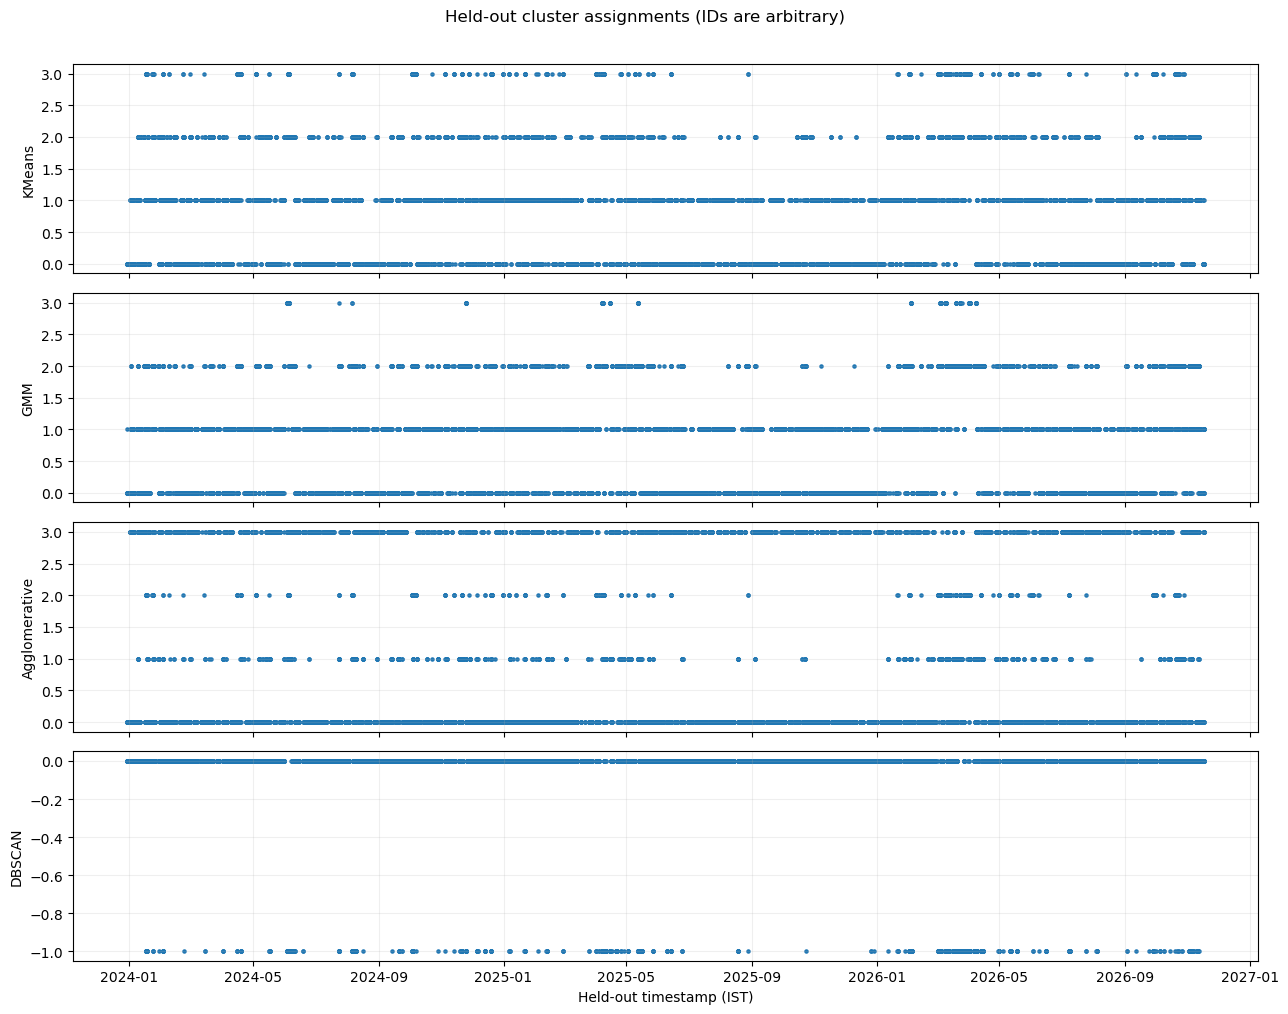

,ret_5,roll_vol,rsi,ma_diff,momentum,atr_pct
cluster,,,,,,
0,0.004244,-0.718230,0.156563,0.212784,0.021124,-0.913616
1,0.010364,-0.117217,-0.068657,-0.050267,0.006328,0.041642
2,0.008714,1.053251,-0.068884,-0.224846,0.008397,1.054792
3,-0.245815,2.915275,-0.216484,-0.298536,-0.278237,2.698377


In [7]:
fig, axes = plt.subplots(len(predictions), 1, figsize=(13, 2.5*len(predictions)), sharex=True)
for ax, (name, labels) in zip(axes, predictions.items()):
    ax.scatter(test_timestamps, labels, s=5)
    ax.set_ylabel(name)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Held-out timestamp (IST)")
fig.suptitle("Held-out cluster assignments (IDs are arbitrary)", y=1.01)
plt.tight_layout()
plt.show()

# Feature profiles for the training GMM clusters, useful for human interpretation.
gmm = models["GMM"]
gmm_train_labels = gmm.predict(Z_train)
profile = pd.DataFrame(Z_train, columns=features.columns).assign(cluster=gmm_train_labels).groupby("cluster").mean()
display(profile)


## 6. Save experiment metadata and read the result responsibly

The notebook does not automatically select or deploy a model. Choose a candidate only after reviewing cluster structure, persistence, noise, stability across time windows, interpretability, and downstream strategy backtests with realistic transaction costs and slippage.

In [8]:
metadata = {
    "dataset": "Bundled NIFTY 50 1-minute CSV files",
    "input_files": [str(p.relative_to(ROOT)) for p in files],
    "raw_rows_after_cleaning": int(len(raw)),
    "resampled_timeframe": "15min",
    "feature_columns": list(features.columns),
    "feature_note": "OHLC-only; volume excluded because historical coverage is incomplete",
    "split": "chronological 70/30",
    "train_rows": int(len(X_train_raw)),
    "test_rows": int(len(X_test_raw)),
    "fit_sample_rows": int(len(Z_train)),
    "heldout_evaluation_rows": int(len(Z_test)),
    "random_state": RANDOM_STATE,
    "log_transformed_columns": log_cols,
    "no_ground_truth_labels": True,
    "limitations": [
        "No independent ground-truth regime labels; accuracy, ARI and NMI are not reported.",
        "Internal clustering metrics do not measure trading profitability.",
        "Agglomerative and DBSCAN held-out predictions use documented proxy methods.",
        "Research features exclude volume for consistent long-term coverage.",
        "Production detector uses a different seven-feature schema; this notebook does not export a production artifact."
    ]
}
(OUT_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved results to:", OUT_DIR.resolve())
print("Review the comparison table and limitations before making a model-selection claim.")


Saved results to: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\real_data_results
Review the comparison table and limitations before making a model-selection claim.
